In [3]:
# Panji Malik Ibrahim_202431202

# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

# Baca dataset
df = pd.read_excel('hasil_scraping_books.xlsx')

# Lihat informasi data
print("=== INFORMASI DATASET ===")
df.info()

# Lihat deskripsi statistik
print("\n=== DESKRIPSI STATISTIK ===")
print(df.describe())

# Cek data kosong
print("\n=== CEK DATA KOSONG ===")
print(df.isna().sum())

# Lihat isi unik kolom target (Rating_Angka)
target_unik = df['Rating_Angka'].unique()
print("\n=== ISI UNIK KOLOM TARGET ===")
print(target_unik)

# Komentar arti tiap kelas target:
# Kelas 1: Rating bintang 1 (Sangat Buruk)
# Kelas 2: Rating bintang 2 (Buruk)
# Kelas 3: Rating bintang 3 (Cukup)
# Kelas 4: Rating bintang 4 (Bagus)
# Kelas 5: Rating bintang 5 (Sangat Bagus)

=== INFORMASI DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Judul_Buku    300 non-null    object 
 1   Harga_GBP     300 non-null    float64
 2   Rating_Angka  300 non-null    int64  
dtypes: float64(1), int64(1), object(1)
memory usage: 7.2+ KB

=== DESKRIPSI STATISTIK ===
        Harga_GBP  Rating_Angka
count  300.000000    300.000000
mean    34.262933      2.916667
std     14.102895      1.441057
min     10.160000      1.000000
25%     21.930000      2.000000
50%     35.520000      3.000000
75%     46.022500      4.000000
max     59.640000      5.000000

=== CEK DATA KOSONG ===
Judul_Buku      0
Harga_GBP       0
Rating_Angka    0
dtype: int64

=== ISI UNIK KOLOM TARGET ===
[3 1 4 5 2]


In [4]:
# Panji Malik Ibrahim_202431202

# Pisahkan fitur x dan target y
X_df = df.drop(columns=['Judul_Buku', 'Rating_Angka'])  # Fitur x: Harga_GBP
y_df = df['Rating_Angka']                              # Target y: Rating_Angka

# Ubah x dan y menjadi array angka
X = np.array(X_df, dtype=np.float64)
y = np.array(y_df, dtype=np.int64)

print("Langkah 7 & 8 Selesai!")
print("Tipe data X:", X.dtype, "| Bentuk X:", X.shape)
print("Tipe data y:", y.dtype, "| Bentuk y:", y.shape)

Langkah 7 & 8 Selesai!
Tipe data X: float64 | Bentuk X: (300, 1)
Tipe data y: int64 | Bentuk y: (300,)


In [5]:
# Panji Malik Ibrahim_202431202

# Bagi data latih dan uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

# Buat model DecisionTreeClassifier() dan latih (fit)
model_dt = DecisionTreeClassifier(random_state=0)
model_dt.fit(X_train, y_train)

print("Langkah Selesai!")
print(f"Jumlah data latih (70%): {len(X_train)} baris")
print(f"Jumlah data uji (30%)  : {len(X_test)} baris")
print("Model Decision Tree berhasil dilatih.")

Langkah Selesai!
Jumlah data latih (70%): 210 baris
Jumlah data uji (30%)  : 90 baris
Model Decision Tree berhasil dilatih.


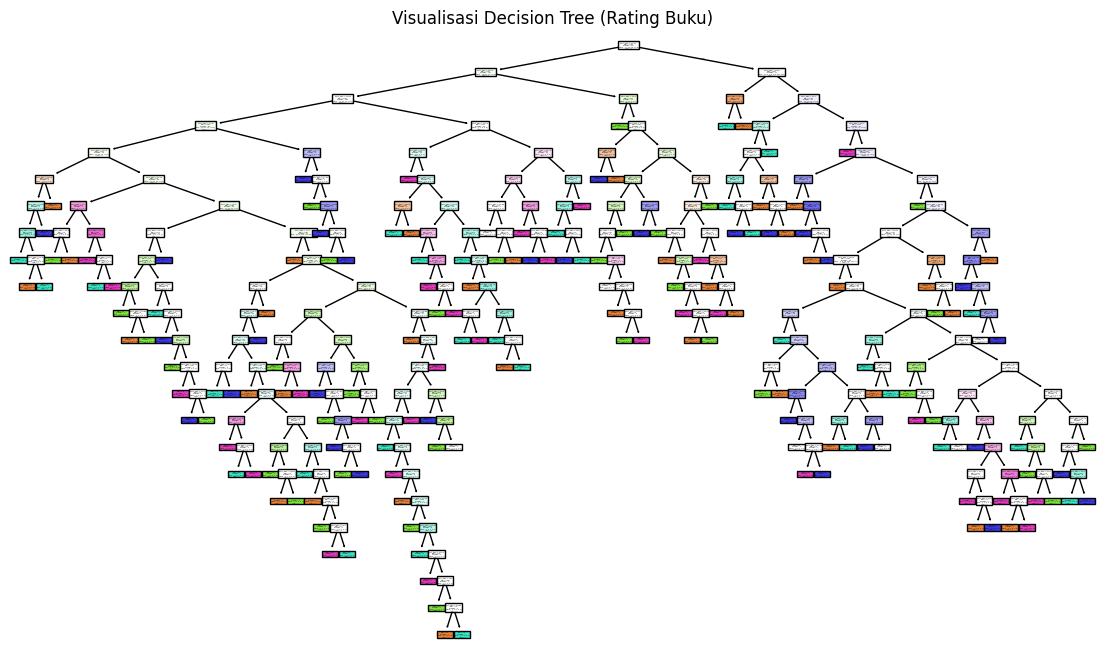

In [6]:
# Panji Malik Ibrahim_202431202

# Tampilkan visualisasi pohon
plt.figure(figsize=(14, 8))
tree.plot_tree(
    model_dt,
    feature_names=['Harga_GBP'],
    class_names=['1', '2', '3', '4', '5'],
    filled=True
)
plt.title("Visualisasi Decision Tree (Rating Buku)")
plt.show()

In [7]:
# Panji Malik Ibrahim_202431202

# Uji dengan 1 data baru
# Contoh: Menguji prediksi kelas rating untuk buku seharga £25.5
data_baru = np.array([[25.5]], dtype=np.float64)
prediksi_baru = model_dt.predict(data_baru)

print("=== UJI PREDIKSI 1 DATA BARU ===")
print(f"Harga Buku Baru : £25.5")
print(f"Hasil Prediksi  : Kelas Rating {prediksi_baru[0]}")

=== UJI PREDIKSI 1 DATA BARU ===
Harga Buku Baru : £25.5
Hasil Prediksi  : Kelas Rating 2


In [8]:
# Panji Malik Ibrahim_202431202

# Prediksi seluruh data uji untuk evaluasi
y_pred = model_dt.predict(X_test)

# Hitung akurasi
akurasi = accuracy_score(y_test, y_pred)
print("=== HASIL AKURASI ===")
print(f"Akurasi Model: {akurasi:.4f} ({akurasi * 100:.2f}%)")

# Tampilkan classification_report
print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred))

=== HASIL AKURASI ===
Akurasi Model: 0.2333 (23.33%)

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           1       0.29      0.20      0.24        20
           2       0.18      0.22      0.20        18
           3       0.25      0.24      0.24        17
           4       0.24      0.29      0.26        14
           5       0.24      0.24      0.24        21

    accuracy                           0.23        90
   macro avg       0.24      0.24      0.23        90
weighted avg       0.24      0.23      0.23        90

